# ShelfSense — Exploratory Data Analysis

Explores the price warehouse through the analytical views in `database/views/analytical_views.sql`.

**Prerequisites:** run `python scripts/setup_database.py --with-data` (or the daily pipeline) so the tables and views are populated.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

from config.db_config import CONNECTION_STRING

# Pin the driver: SQLAlchemy 2.1+ defaults postgresql:// to psycopg 3
engine = create_engine(CONNECTION_STRING.replace("postgresql://", "postgresql+psycopg2://", 1))
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False, "axes.spines.right": False})

# Same colour-blind-validated palette as the Streamlit dashboard (dashboard/charts.py)
RETAILER_COLORS = {"BigBasket": "#2a78d6", "Blinkit": "#eb6834", "Zepto": "#1baf7a", "JioMart": "#eda100"}

def q(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

## 1. Dataset overview

In [2]:
q("""
    SELECT
        (SELECT COUNT(*) FROM dim_product)                        AS products,
        (SELECT COUNT(*) FROM dim_retailer)                       AS retailers,
        (SELECT COUNT(*) FROM fact_price_history)                 AS price_observations,
        (SELECT MIN(price_date) FROM fact_price_history)          AS first_date,
        (SELECT MAX(price_date) FROM fact_price_history)          AS last_date,
        (SELECT ROUND(AVG((NOT is_available)::INT) * 100, 2)
           FROM fact_price_history)                               AS stockout_rate_pct
""")

,products,retailers,price_observations,first_date,last_date,stockout_rate_pct
0,75,4,27000,2026-07-20,2026-10-17,3.44


## 2. Who discounts most aggressively? (last 7 days)

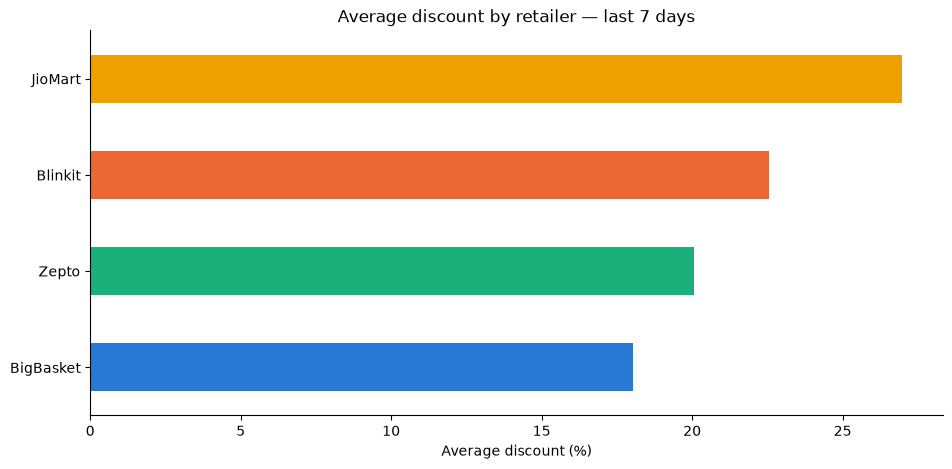

,bigbasket_avg_discount,blinkit_avg_discount,zepto_avg_discount,jiomart_avg_discount,market_avg_discount
category_name,,,,,
Rice & Grains,18.91,24.35,22.05,27.76,23.30
Detergent,18.83,21.50,23.87,27.35,22.97
Spices & Masala,19.29,21.89,20.86,29.52,22.83
Cooking Oil,17.40,23.84,20.39,29.15,22.74
Soft Drinks & Juices,17.79,22.73,18.03,30.87,22.44
Toothpaste,19.62,23.49,19.85,27.06,22.44
Dishwash,18.13,23.21,20.79,26.94,22.27
Tea & Coffee,18.30,22.66,20.01,27.01,22.01
Soap & Bodywash,18.19,21.01,20.42,27.77,21.87


In [3]:
weekly = q("SELECT * FROM vw_weekly_discount_analysis").set_index("category_name")
retailer_cols = ["bigbasket_avg_discount", "blinkit_avg_discount", "zepto_avg_discount", "jiomart_avg_discount"]
names = {"bigbasket_avg_discount": "BigBasket", "blinkit_avg_discount": "Blinkit",
         "zepto_avg_discount": "Zepto", "jiomart_avg_discount": "JioMart"}
avg = weekly[retailer_cols].mean().rename(names).sort_values()
avg.plot.barh(color=[RETAILER_COLORS[r] for r in avg.index])
plt.ylabel("")
plt.xlabel("Average discount (%)")
plt.title("Average discount by retailer — last 7 days")
plt.show()
weekly.head(10)

## 3. Weekend vs weekday promotion strategy

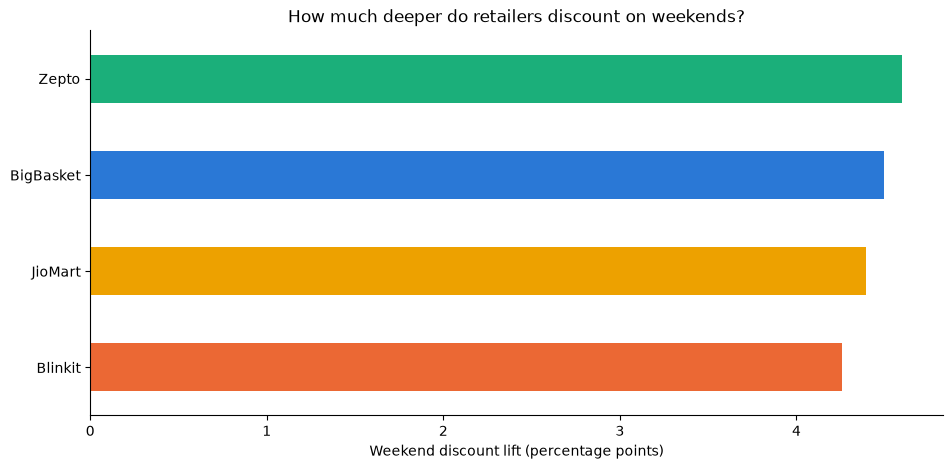

pricing_strategy,Consistent Pricing,Weekend-Heavy Promoter
retailer_name,,
BigBasket,0,20
Blinkit,0,20
JioMart,1,19
Zepto,0,20


In [4]:
wk = q("SELECT * FROM vw_weekend_vs_weekday_discounts")
lift = wk.groupby("retailer_name")["weekend_discount_lift_ppt"].mean().sort_values()
lift.plot.barh(color=[RETAILER_COLORS[r] for r in lift.index])
plt.xlabel("Weekend discount lift (percentage points)")
plt.ylabel("")
plt.title("How much deeper do retailers discount on weekends?")
plt.show()
pd.crosstab(wk["retailer_name"], wk["pricing_strategy"])

## 4. Who wins on price most often?

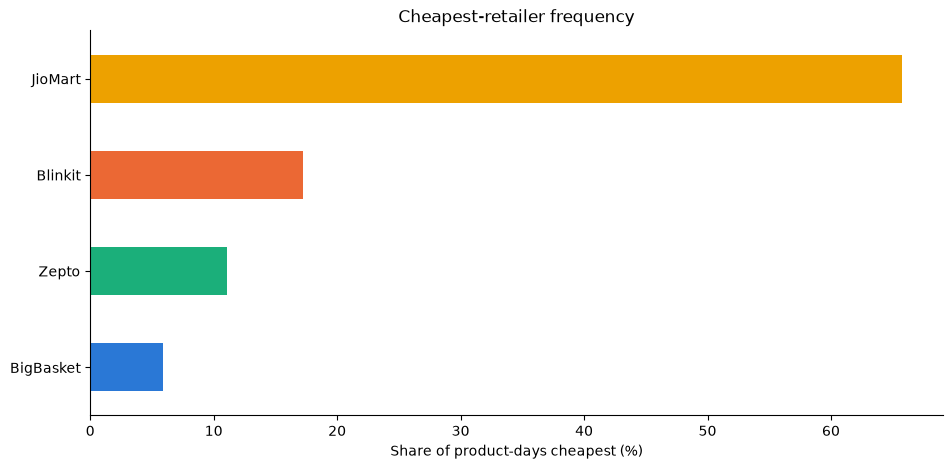

In [5]:
cheapest = q("""
    SELECT retailer_name, SUM(days_cheapest) AS days_cheapest
    FROM vw_cheapest_retailer_frequency
    GROUP BY retailer_name
""").set_index("retailer_name")["days_cheapest"]
share = (cheapest / cheapest.sum() * 100).sort_values()
share.plot.barh(color=[RETAILER_COLORS[r] for r in share.index])
plt.xlabel("Share of product-days cheapest (%)")
plt.ylabel("")
plt.title("Cheapest-retailer frequency")
plt.show()

## 5. Category price index (day 1 = 100, 7-day moving average)

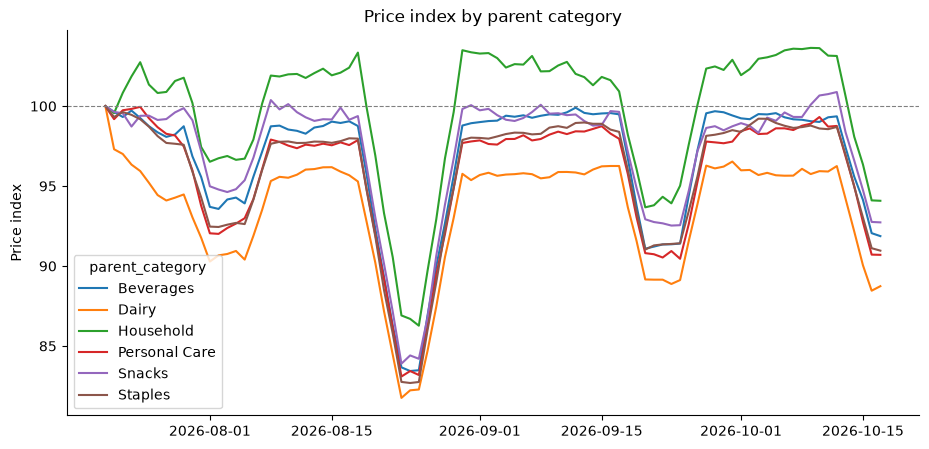

In [6]:
idx = q("SELECT price_date, parent_category, price_index_7day_ma FROM vw_category_price_index")
by_parent = idx.groupby(["price_date", "parent_category"])["price_index_7day_ma"].mean().unstack()
by_parent.plot()
plt.axhline(100, color="grey", lw=0.8, ls="--")
plt.ylabel("Price index")
plt.xlabel("")
plt.title("Price index by parent category")
plt.show()

## 6. Price volatility — which products need closest monitoring?

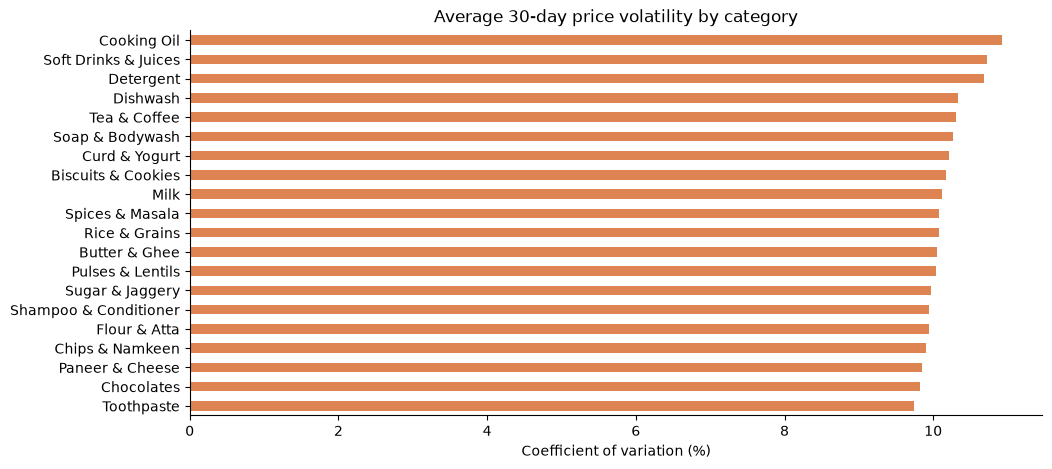

,product_name,category_name,retailer_name,min_price_30d,max_price_30d,avg_price_30d,volatility_index_pct
0,Fortune Sunlite Refined Oil,Cooking Oil,JioMart,432.94,730.54,607.11,14.30
1,Figaro Olive Oil,Cooking Oil,JioMart,348.74,629.71,517.62,13.94
2,Fortune Chana Dal,Pulses & Lentils,JioMart,72.89,121.53,102.44,13.88
3,Mother Dairy Cow Ghee,Butter & Ghee,JioMart,340.31,543.07,449.05,13.24
4,India Gate Basmati Rice,Rice & Grains,JioMart,321.11,531.15,446.51,13.22
5,Haldiram Aloo Bhujia,Chips & Namkeen,JioMart,84.98,138.21,117.85,13.20
6,BB Royal Rajma,Pulses & Lentils,JioMart,107.15,177.66,146.73,13.17
7,Lux Soft Glow Body Wash,Soap & Bodywash,JioMart,96.02,155.33,129.15,13.15
8,Organic Tattva Jaggery Powder,Sugar & Jaggery,JioMart,95.91,159.07,130.44,13.07
9,Amul Fresh Paneer,Paneer & Cheese,JioMart,54.48,84.32,72.26,13.06


In [7]:
vol = q("SELECT * FROM vw_price_volatility")
vol.groupby("category_name")["volatility_index_pct"].mean().sort_values().plot.barh(color="#dd8452")
plt.xlabel("Coefficient of variation (%)")
plt.ylabel("")
plt.title("Average 30-day price volatility by category")
plt.show()
vol.head(10)

## 7. Inflation: absorbing or passing on?

In [8]:
infl = q("SELECT * FROM vw_inflation_adjusted_pricing WHERE cpi_index IS NOT NULL")
pd.crosstab(infl["category_name"], infl["inflation_strategy"])

inflation_strategy,Absorbing Inflation
category_name,
Biscuits & Cookies,4
Butter & Ghee,4
Chips & Namkeen,4
Chocolates,4
Cooking Oil,4
Curd & Yogurt,4
Detergent,4
Dishwash,4
Flour & Atta,4


## 8. Promotional calendar — longest promotions

In [9]:
q("""
    SELECT retailer_name, product_name, promo_start_date, promo_end_date,
           promo_duration_days, avg_promo_discount
    FROM vw_promotional_calendar
    ORDER BY promo_duration_days DESC
    LIMIT 15
""")

,retailer_name,product_name,promo_start_date,promo_end_date,promo_duration_days,avg_promo_discount
0,JioMart,5 Star 3D Chocolate Bar,2026-07-30,2026-08-30,32,26.34
1,JioMart,Nescafe Classic Instant Coffee,2026-07-31,2026-08-27,28,25.62
2,JioMart,Exo Dishwash Bar,2026-07-23,2026-08-17,26,24.11
3,JioMart,Ferrero Rocher Pack,2026-08-08,2026-08-30,23,24.98
4,JioMart,Exo Dishwash Bar,2026-08-30,2026-09-21,23,25.50
5,JioMart,KitKat 4 Finger,2026-07-20,2026-08-09,21,23.49
6,JioMart,Amul Masti Dahi,2026-09-17,2026-10-05,19,24.49
7,JioMart,Britannia Cheese Block,2026-09-29,2026-10-17,19,24.41
8,JioMart,Kohinoor Super Value Basmati,2026-09-29,2026-10-17,19,23.38
9,JioMart,Dove Hair Fall Rescue Shampoo,2026-09-03,2026-09-20,18,26.14
